# Jawad Hassan 2230-0035
# BS AI
# CV LAB # 5
# Sir Zeeshan Aslam



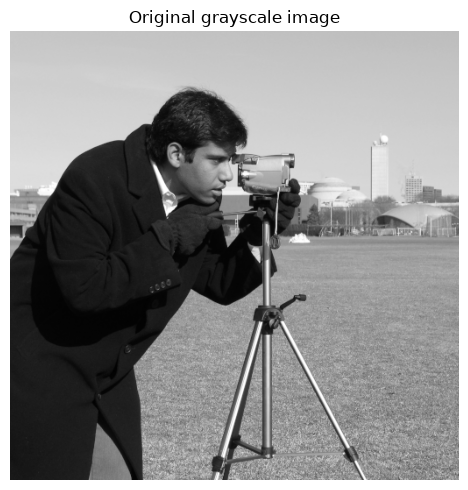

Shape: (512, 512) dtype: uint8 range: (np.uint8(0), np.uint8(255))


In [2]:
# Setup - Input Images
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import data, img_as_ubyte, feature

def show_images(images, titles, figsize=None, cmaps=None):
    if figsize is None:
        figsize = (4 * len(images), 4)
    if cmaps is None:
        cmaps = ["gray"] * len(images)
    plt.figure(figsize=figsize)
    for i, (im, title, cmap) in enumerate(zip(images, titles, cmaps), start=1):
        plt.subplot(1, len(images), i)
        plt.imshow(im, cmap=cmap)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

image = img_as_ubyte(data.camera())
show_images([image], ["Original grayscale image"], figsize=(5, 5))
print("Shape:", image.shape, "dtype:", image.dtype,
      "range:", (image.min(), image.max()))

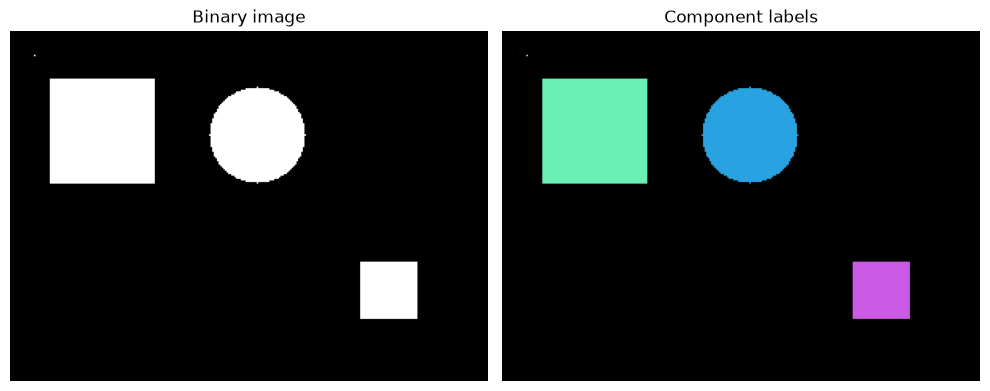

Foreground component count: 4
Label 1: area=1, bbox=(15,15,1,1), centroid=(15.0,15.0)
Label 2: area=4356, bbox=(25,30,66,66), centroid=(57.5,62.5)
Label 3: area=2821, bbox=(125,35,61,61), centroid=(155.0,65.0)
Label 4: area=1296, bbox=(220,145,36,36), centroid=(237.5,162.5)


In [3]:
# Experiment 1 - Extraction of Connected Components
binary = np.zeros((220, 300), dtype=np.uint8)
cv2.rectangle(binary, (25, 30), (90, 95), 255, -1)
cv2.circle(binary, (155, 65), 30, 255, -1)
cv2.rectangle(binary, (220, 145), (255, 180), 255, -1)
binary[15, 15] = 255  # isolated foreground pixel

n, labels, stats, centroids = cv2.connectedComponentsWithStats(
    (binary > 0).astype(np.uint8), connectivity=8
)

rng = np.random.default_rng(4)
colors = rng.integers(0, 255, size=(n, 3), dtype=np.uint8)
colors[0] = [0, 0, 0]
label_rgb = colors[labels]

show_images([binary, label_rgb], ["Binary image", "Component labels"], figsize=(10, 4),
            cmaps=["gray", None])

print("Foreground component count:", n - 1)
for i in range(1, n):
    x, y, w, h, area = stats[i]
    cx, cy = centroids[i]
    print(f"Label {i}: area={area}, bbox=({x},{y},{w},{h}), centroid=({cx:.1f},{cy:.1f})")

# Lab Activity Q: Explain how poor thresholding can split one object or merge several objects.
# A: Connected-component labeling only sees which pixels are foreground after thresholding
#    - it has no idea what the "real" object looked like. If the threshold is set too high,
#    part of one real object can drop below it and become background, cutting that single
#    object into two or more separate labeled components (a SPLIT). If the threshold is too
#    low, noise or faint background texture between two nearby real objects can get pulled
#    into the foreground, forming a thin bridge that connects them into one labeled
#    component (a MERGE) even though they were physically separate. Either way, the area,
#    bounding-box, and centroid statistics reported below become wrong - bad thresholding
#    corrupts the component count and shapes before any morphology is even applied.

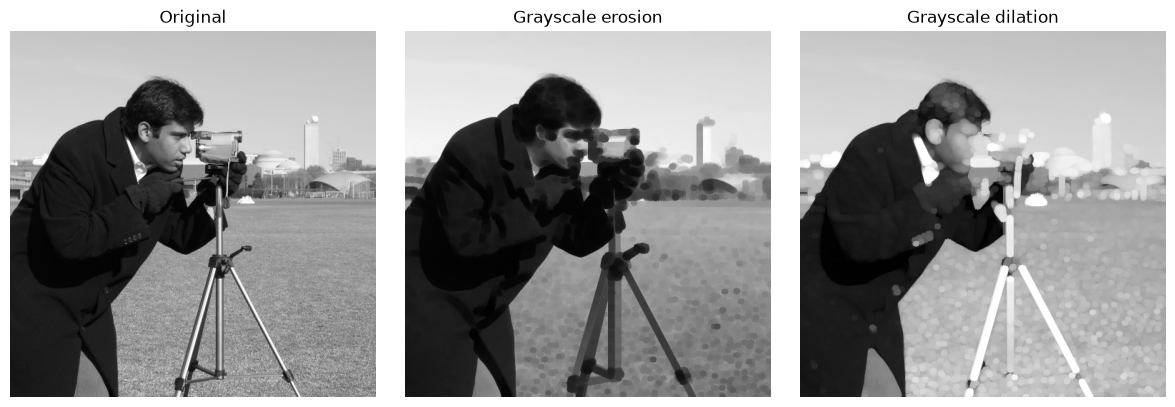

In [4]:
# Experiment 2 - Erosion and Dilation of Grayscale Images
gray = image.copy()
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))

eroded = cv2.erode(gray, k)
dilated = cv2.dilate(gray, k)

show_images([gray, eroded, dilated],
            ["Original", "Grayscale erosion", "Grayscale dilation"],
            figsize=(12, 4))

# Lab Activity Q: Explain the local-minimum and local-maximum interpretations.
# A: On a binary image, erosion/dilation only ask "is the neighborhood all-foreground?" /
#    "does the neighborhood touch any foreground?" - a yes/no test. On a GRAYSCALE image
#    there's no simple foreground/background, so the operations generalize to intensity:
#    erosion replaces each pixel with the MINIMUM intensity found under the SE, and
#    dilation replaces each pixel with the MAXIMUM intensity found under the SE. This means
#    erosion darkens the image overall and shrinks/thins small BRIGHT regions (a bright
#    highlight gets pulled down toward its darker surroundings, and dark regions expand),
#    while dilation brightens the image overall and shrinks/thins small DARK regions (a
#    dark shadow or valley gets pulled up toward its brighter surroundings, and bright
#    regions expand). In short: erosion = "local min filter" (bright details shrink, dark
#    details grow), dilation = "local max filter" (dark details shrink, bright details grow)
#    - the binary case is just the special two-level (0/255) version of this same rule.

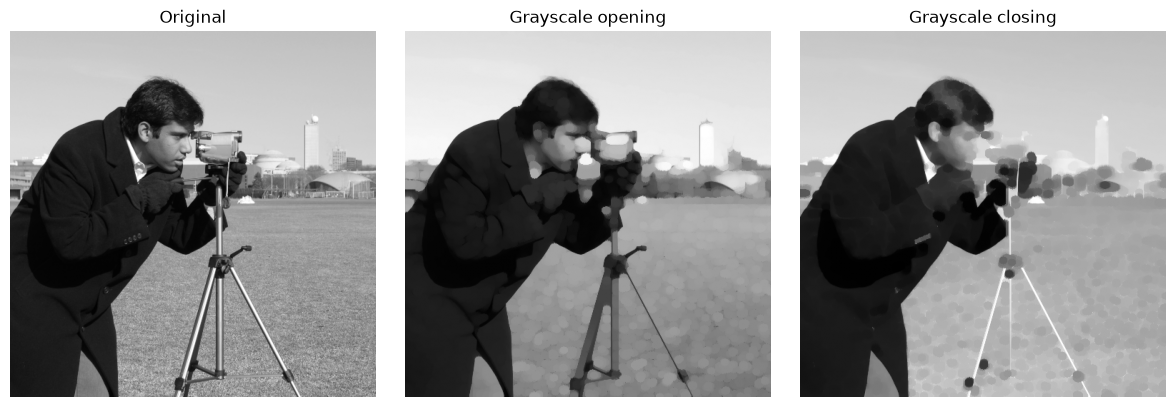

In [5]:
# Experiment 3 - Opening and Closing of Grayscale Images
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))

opened = cv2.morphologyEx(gray, cv2.MORPH_OPEN, k)
closed = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, k)

show_images([gray, opened, closed],
            ["Original", "Grayscale opening", "Grayscale closing"],
            figsize=(12, 4))

# Lab Activity Q: Explain why opening and closing are not generally interchangeable.
# A: Opening (erode then dilate) and closing (dilate then erode) are each other's dual, not
#    each other's inverse - they target OPPOSITE kinds of detail. Opening's first step
#    (erosion) is a local-minimum filter, so it permanently deletes small BRIGHT structures
#    (they get pulled down to their darker surroundings) before the dilation step restores
#    the size of whatever survived - bright specks/peaks smaller than the SE are gone for
#    good and dilation cannot bring them back. Closing's first step (dilation) is a
#    local-maximum filter, so it fills in/removes small DARK structures (valleys, dark
#    specks get pulled up to their brighter surroundings) before erosion restores overall
#    size - dark details smaller than the SE are gone for good too. Because opening can
#    only destroy bright details and closing can only destroy dark details, running one
#    after the other (or swapping which one you apply) does NOT undo or substitute for the
#    other - each is a one-directional filter on intensity, not a reversible pair.

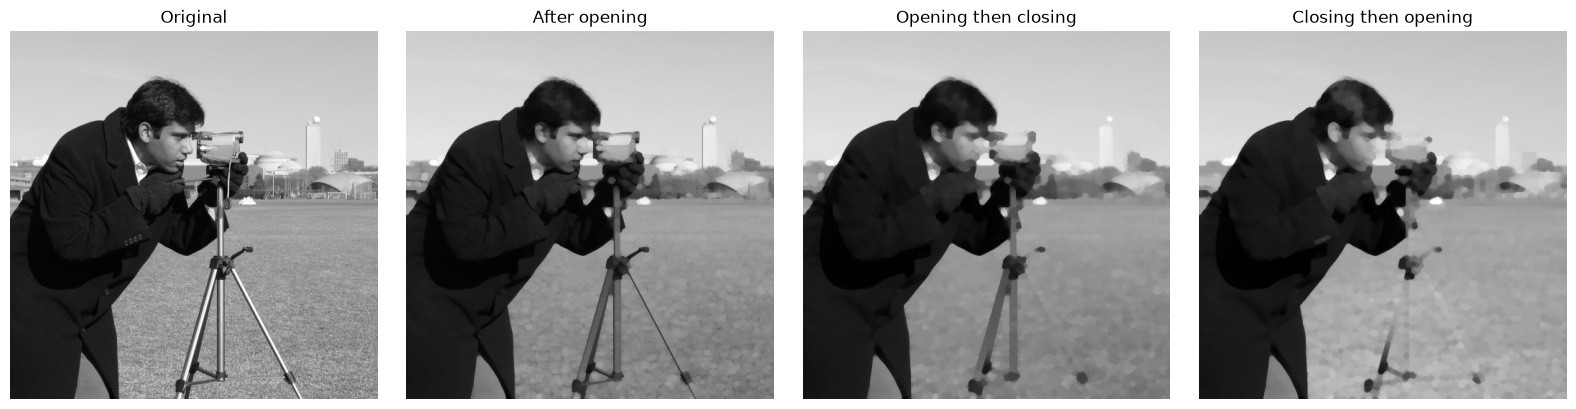

In [6]:
# Experiment 4 - Morphological Smoothing
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

opened = cv2.morphologyEx(gray, cv2.MORPH_OPEN, k)
smoothed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, k)

reverse_order = cv2.morphologyEx(
    cv2.morphologyEx(gray, cv2.MORPH_CLOSE, k),
    cv2.MORPH_OPEN, k
)

show_images([gray, opened, smoothed, reverse_order],
            ["Original", "After opening", "Opening then closing", "Closing then opening"],
            figsize=(16, 4))

# Lab Activity Q: Compare opening-then-closing with closing-then-opening.
# A: "Opening then closing" (smoothed) first deletes small BRIGHT details (opening), then
#    deletes small DARK details on what remains (closing) - so bright noise is removed
#    before dark noise gets a chance to be affected by it. "Closing then opening"
#    (reverse_order) does it backwards: dark details are removed first, then bright details
#    are removed from that already-modified image. Because erosion/dilation are nonlinear
#    (min/max, not averaging), the order changes the intermediate image each step operates
#    on, so the two results are generally NOT identical, even though both suppress small
#    bright and dark details overall. In practice the two look similar for well-separated
#    noise, but can diverge visibly near edges where bright and dark details are close
#    together, since whichever filter runs first "claims" that boundary pixel's value
#    before the second filter ever sees it.

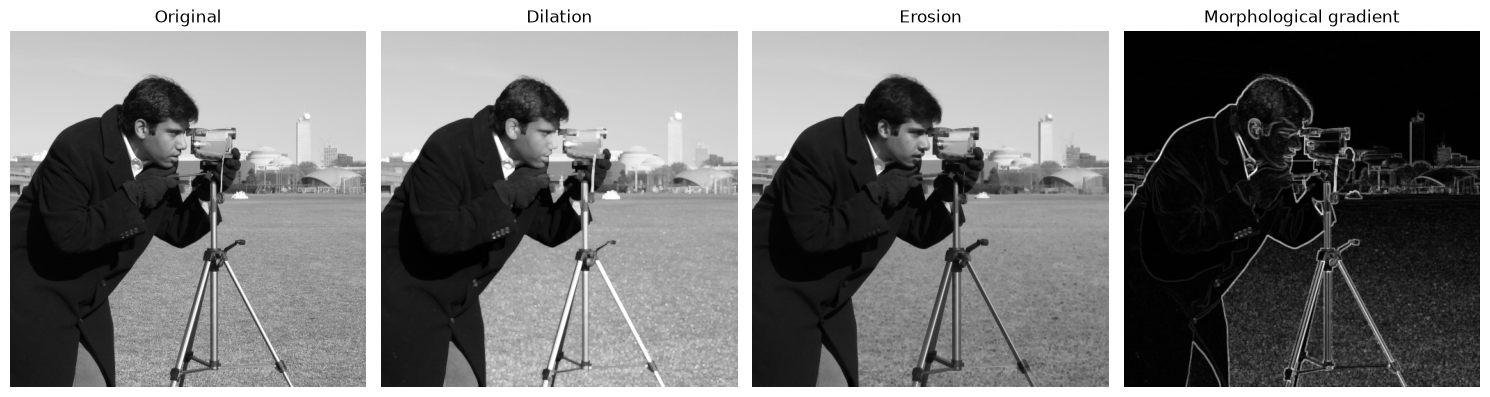

In [7]:
# Experiment 5 - Morphological Gradient
k = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

dil = cv2.dilate(gray, k)
ero = cv2.erode(gray, k)
gradient = cv2.subtract(dil, ero)

show_images([gray, dil, ero, gradient],
            ["Original", "Dilation", "Erosion", "Morphological gradient"],
            figsize=(15, 4))

# Lab Activity Q: Compare the result with Sobel gradient magnitude and explain differences.
# A: Sobel computes a directional derivative approximation (separate horizontal/vertical
#    kernels, combined as sqrt(Gx^2 + Gy^2)) - it's a LINEAR filter based on weighted sums,
#    sensitive mainly to intensity change ALONG specific directions, and tends to produce
#    thinner, more precisely-located edges with a smoother response to noise (since it's
#    essentially a smoothed derivative).
#    The morphological gradient (dilation - erosion) is a NONLINEAR, direction-independent
#    measure: it reports the full local intensity RANGE (max - min) inside the SE at every
#    pixel, regardless of which direction the change happens in. This makes it react
#    strongly to any local contrast (including texture/noise, not just "real" edges), and
#    the resulting edge band is typically thicker than Sobel's (its width scales with SE
#    size, not with how sharp the underlying transition is). In short: Sobel approximates a
#    derivative and favors directional, thin edges; morphological gradient approximates a
#    local range/contrast measure and produces thicker, isotropic, noise-sensitive edges.

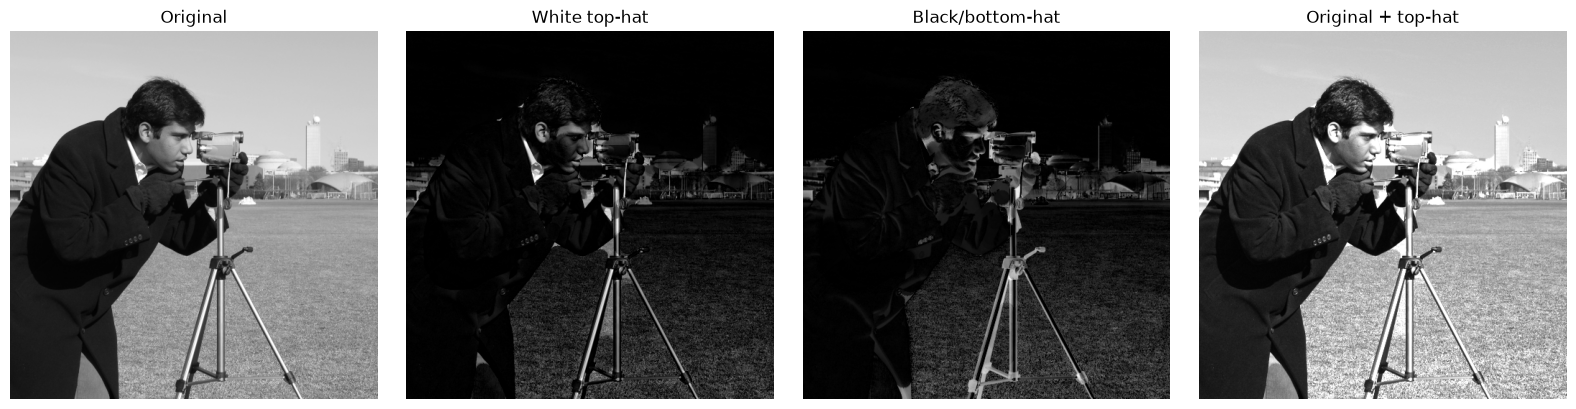

In [8]:
# Experiment 6 - Top-Hat and Bottom-Hat Transformations
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))

white_tophat = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, k)
black_tophat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, k)
enhanced = cv2.add(gray, white_tophat)

show_images([gray, white_tophat, black_tophat, enhanced],
            ["Original", "White top-hat", "Black/bottom-hat", "Original + top-hat"],
            figsize=(16, 4))

# Lab Activity Q: Explain why SE size should reflect the scale of features and background
# variation.
# A: Top-hat = original - opening(original); opening removes anything SMALLER than the SE
#    while leaving anything LARGER than the SE roughly untouched. So top-hat only keeps
#    bright features that are smaller than the SE - if the SE is too small, it won't fully
#    "erase" the background/large structures during opening, so subtracting leaves residual
#    large-scale content mixed in with the real small features (noisy, messy result). If the
#    SE is too big, it starts treating genuinely meaningful features (that are smaller than
#    the oversized SE but still important) as "background" to be removed by opening, so they
#    get incorrectly extracted as top-hat features too, or conversely a too-large SE can
#    over-smooth the opening step so much that it no longer tracks slow illumination drift
#    accurately. The same logic applies to bottom-hat (closing then subtract) for dark
#    features. In short: the SE must be larger than the small features you want to KEEP
#    untouched by the open/close step, but smaller than the scale of the slow background
#    variation (e.g. uneven illumination) you want top-hat/bottom-hat to isolate - picking
#    the wrong size either leaves background contamination in the result or deletes the
#    real features you were trying to extract.

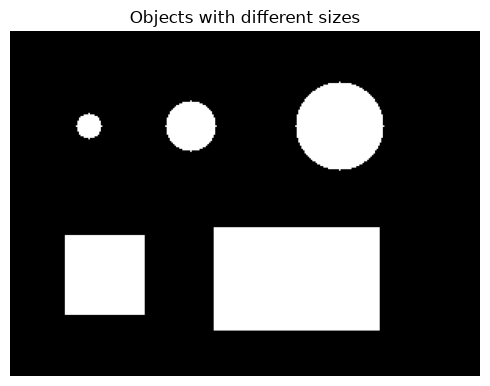

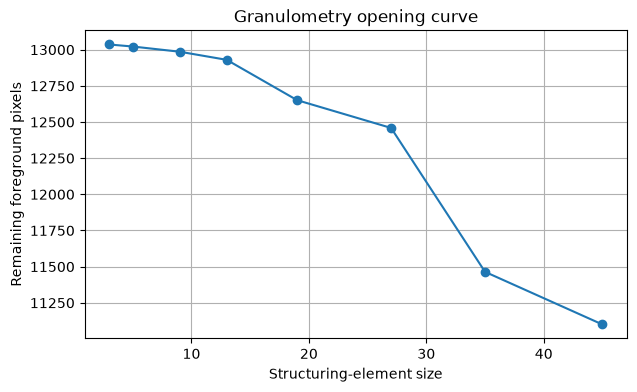

[(3, np.int64(13036)), (5, np.int64(13022)), (9, np.int64(12986)), (13, np.int64(12930)), (19, np.int64(12651)), (27, np.int64(12459)), (35, np.int64(11464)), (45, np.int64(11100))]


In [9]:
# Experiment 7 - Granulometry
gran = np.zeros((220, 300), dtype=np.uint8)
cv2.circle(gran, (50, 60), 8, 255, -1)
cv2.circle(gran, (115, 60), 16, 255, -1)
cv2.circle(gran, (210, 60), 28, 255, -1)
cv2.rectangle(gran, (35, 130), (85, 180), 255, -1)
cv2.rectangle(gran, (130, 125), (235, 190), 255, -1)

sizes = [3, 5, 9, 13, 19, 27, 35, 45]
remaining = []
for size in sizes:
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    opened = cv2.morphologyEx(gran, cv2.MORPH_OPEN, se)
    remaining.append(np.count_nonzero(opened))

show_images([gran], ["Objects with different sizes"], figsize=(5, 4))

plt.figure(figsize=(7, 4))
plt.plot(sizes, remaining, marker="o")
plt.xlabel("Structuring-element size")
plt.ylabel("Remaining foreground pixels")
plt.title("Granulometry opening curve")
plt.grid(True)
plt.show()

print(list(zip(sizes, remaining)))

# Lab Activity Q: Explain how the curve changes as the SE grows.
# A: Opening with SE size S removes any foreground structure that can't fully contain an
#    SxS (ellipse-shaped) neighborhood - so as the loop size increases, each pass removes
#    progressively LARGER objects on top of whatever was already removed by smaller sizes.
#    The remaining-pixel curve is therefore monotonically non-increasing (it can only stay
#    flat or drop, never go back up), and it drops in STEPS rather than smoothly: the curve
#    stays roughly flat while the SE is smaller than every object (nothing is removed yet),
#    then drops sharply right around the SE size that matches an object's own size (that
#    object disappears all at once), then flattens again until the SE reaches the next
#    object's size. With 3 circles (radius ~8, 16, 28) and 2 rectangles in this image, you
#    should see roughly one noticeable drop-off per distinct object scale, and the curve
#    reaches (near) zero once the SE is larger than even the biggest object (the 235x65
#    rectangle). The size (x-position) of each drop tells you the scale of structures
#    present, and the height of each drop tells you how much foreground area belongs to
#    objects of roughly that scale - this is exactly the "particle size distribution" idea
#    granulometry is approximating.

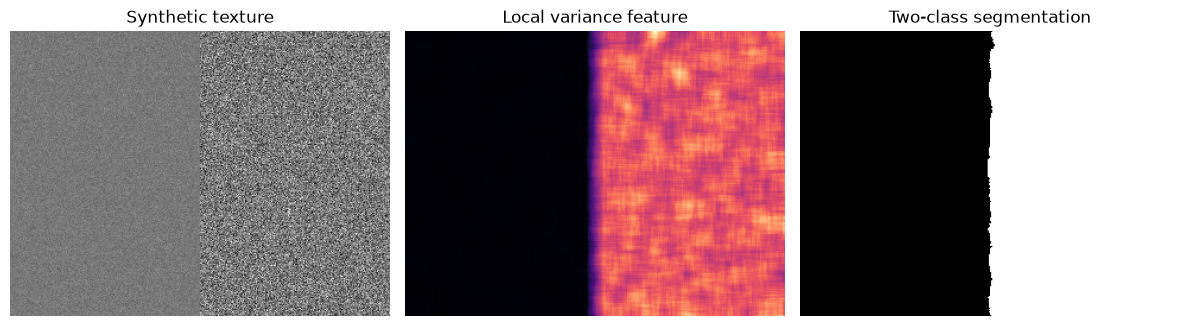

Feature range: 41.541015625 1889.9248046875


In [10]:
# Experiment 8 - Textural Segmentation
rng = np.random.default_rng(7)
texture = np.zeros((240, 320), dtype=np.uint8)
texture[:, :160] = np.clip(120 + rng.normal(0, 8, (240, 160)), 0, 255)
texture[:, 160:] = np.clip(120 + rng.normal(0, 35, (240, 160)), 0, 255)
texture = texture.astype(np.uint8)

f = texture.astype(np.float32)
mean = cv2.blur(f, (15, 15))
mean_sq = cv2.blur(f * f, (15, 15))
local_variance = np.maximum(mean_sq - mean * mean, 0)
threshold = np.median(local_variance)
segments = (local_variance > threshold).astype(np.uint8)

show_images([texture, local_variance, segments],
            ["Synthetic texture", "Local variance feature", "Two-class segmentation"],
            figsize=(12, 4), cmaps=["gray", "magma", "gray"])

print("Feature range:", float(local_variance.min()), float(local_variance.max()))

# Lab Activity Q: Discuss how illumination variation and noise can confuse texture
# segmentation.
# A: This method segments purely on LOCAL VARIANCE (how much pixel values fluctuate in a
#    window), not on mean brightness - which is the whole point here (both halves have the
#    same mean ~120 but different variance). The risk is that several other things also
#    raise local variance besides "real" texture: (1) Uneven illumination creates smooth
#    brightness gradients across the image; near a strong gradient, pixels within one
#    window span a wide range of values purely due to lighting, not texture, inflating
#    variance and making a flat/smooth region look falsely "textured." (2) Sensor/image
#    noise (grain, compression artifacts) adds small random fluctuations everywhere,
#    raising the variance floor globally and shrinking the gap between the "low-texture"
#    and "high-texture" classes, which makes a single global threshold (np.median here)
#    less reliable - noisy "smooth" regions can cross the threshold and get misclassified
#    as high-texture. (3) Near object edges, a window straddling two different flat regions
#    also shows high variance even though neither side is actually textured, causing false
#    positives right at boundaries. Mitigations include denoising first, using illumination
#    correction (e.g. subtracting a heavily-blurred version of the image), or adapting the
#    threshold locally instead of using one global value.

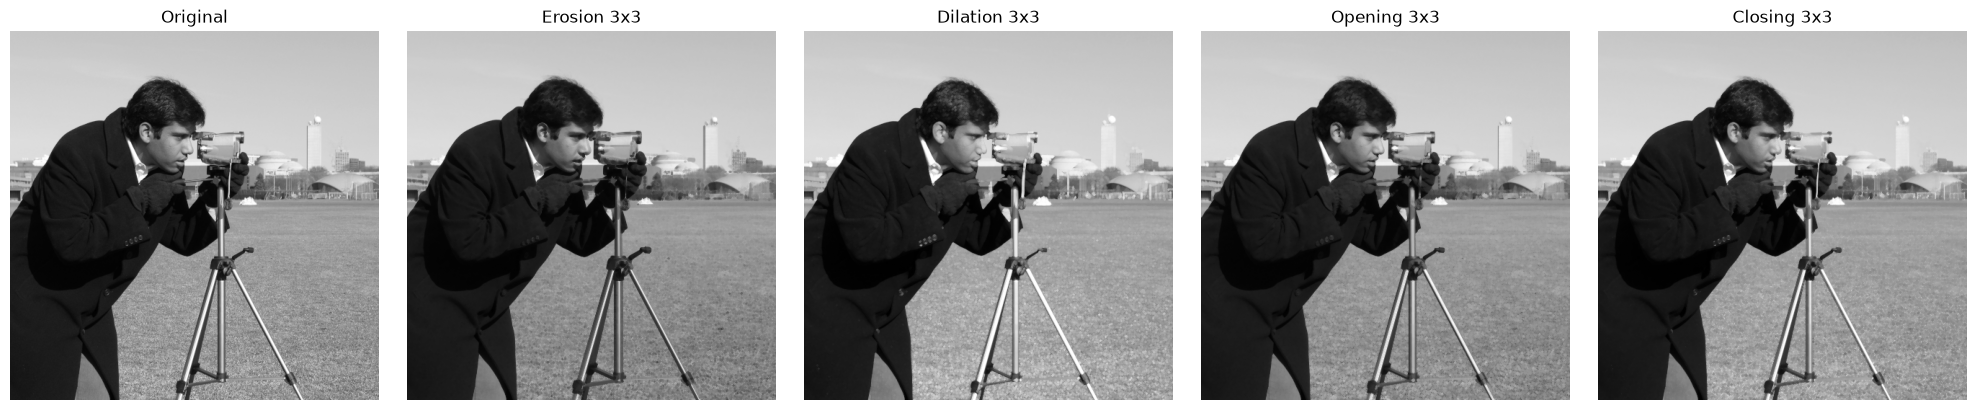

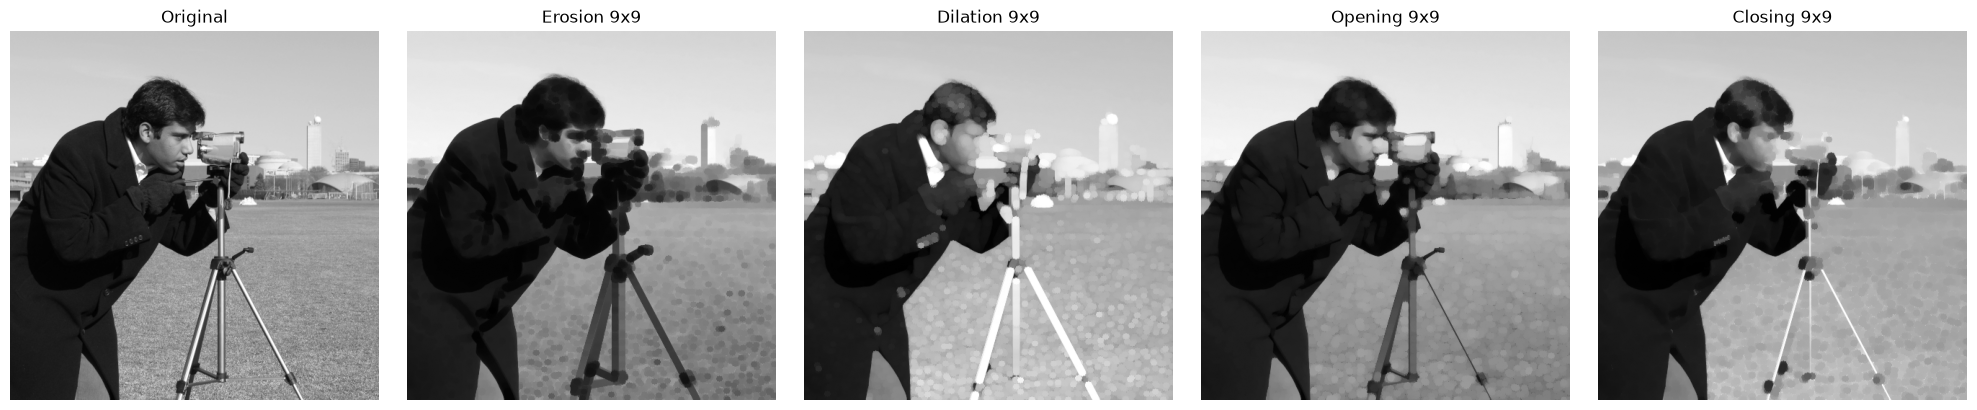

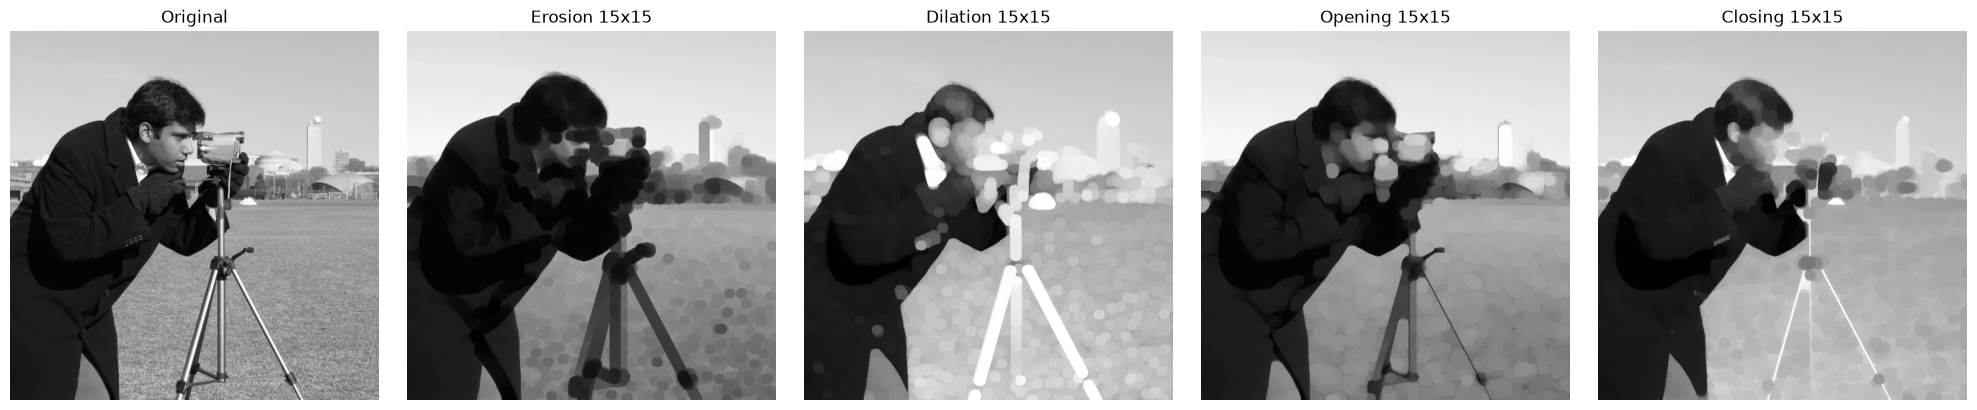

In [11]:
# Lab Task 1 - Grayscale Erosion, Dilation, Opening, Closing at Three SE Sizes
gray_task = image.copy()  # cameraman image: has bright highlights (sky, face) and dark details (coat, tripod)

se_sizes = [3, 9, 15]
for size in se_sizes:
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    er = cv2.erode(gray_task, se)
    di = cv2.dilate(gray_task, se)
    op = cv2.morphologyEx(gray_task, cv2.MORPH_OPEN, se)
    cl = cv2.morphologyEx(gray_task, cv2.MORPH_CLOSE, se)
    show_images(
        [gray_task, er, di, op, cl],
        ["Original", f"Erosion {size}x{size}", f"Dilation {size}x{size}",
         f"Opening {size}x{size}", f"Closing {size}x{size}"],
        figsize=(20, 4)
    )

# Lab Task 1 Observation:
# As SE size grows from 3x3 to 15x15, every effect gets stronger in the same direction:
# - Erosion gets progressively darker and erases progressively bigger bright highlights
#   (e.g. the sky and the bright parts of the face/camera shrink and dim more at 15x15).
# - Dilation gets progressively brighter and erases progressively bigger dark details
#   (e.g. the dark coat and tripod legs thin out and brighten more at 15x15).
# - Opening removes progressively larger bright structures while keeping large-scale
#   brightness roughly intact - small bright texture/noise disappears first, larger bright
#   regions survive until the SE grows enough to remove them too.
# - Closing fills in progressively larger dark structures - fine dark texture (coat creases,
#   thin tripod legs) disappears first, larger dark regions survive until the SE catches up.

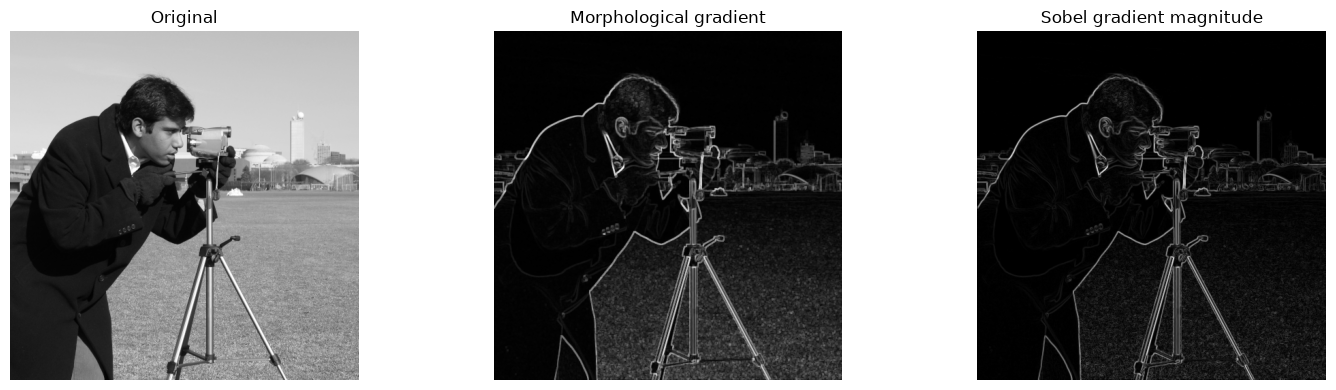

In [13]:
# Lab Task 2 - Morphological Gradient vs. Sobel Edge Magnitude
k = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
morph_gradient = cv2.subtract(cv2.dilate(gray_task, k), cv2.erode(gray_task, k))

sobel_x = cv2.Sobel(gray_task, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_task, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_mag = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

show_images([gray_task, morph_gradient, sobel_mag],
            ["Original", "Morphological gradient", "Sobel gradient magnitude"],
            figsize=(15, 4))

# Lab Task 2 Comparison:
# Sobel computes a LINEAR derivative approximation using separate horizontal/vertical
# kernels, then combines them as sqrt(Gx^2 + Gy^2) - it responds to directional intensity
# change and tends to give thin, precisely-located edges with lower noise sensitivity.
# The morphological gradient (dilation - erosion) is NONLINEAR: it reports the full local
# intensity range (local max - local min) inside the 3x3 SE, with no notion of direction.
# It reacts to ANY local contrast - including fine texture/noise, not just "real" edges -
# and produces a thicker edge band whose width scales with SE size rather than with how
# sharp the actual transition is. Visually, Sobel edges should look crisper/thinner while
# the morphological gradient looks slightly thicker/bolder, especially in textured regions.

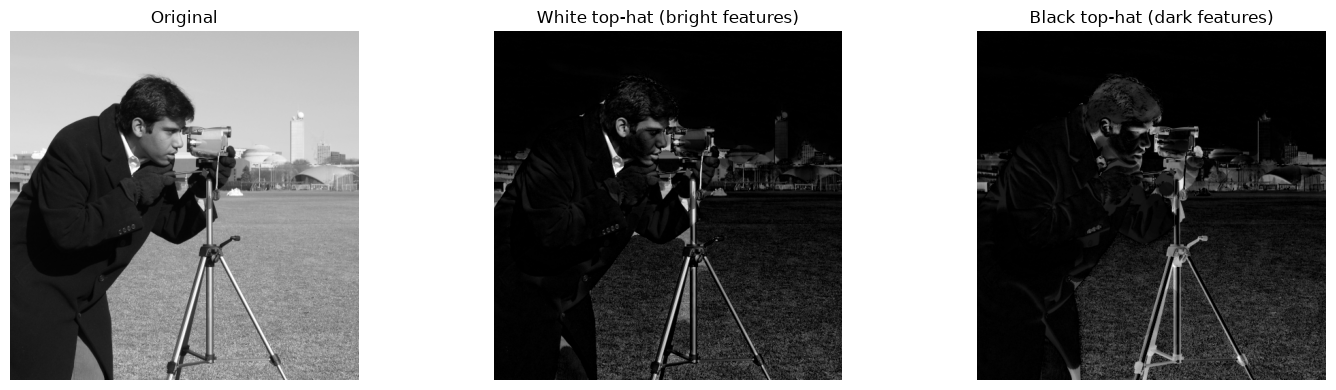

In [14]:
# Lab Task 3 - Top-Hat and Bottom-Hat for Different Feature Types
k_th = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
white_th = cv2.morphologyEx(gray_task, cv2.MORPH_TOPHAT, k_th)
black_th = cv2.morphologyEx(gray_task, cv2.MORPH_BLACKHAT, k_th)

show_images([gray_task, white_th, black_th],
            ["Original", "White top-hat (bright features)", "Black top-hat (dark features)"],
            figsize=(15, 4))

# Lab Task 3 Explanation:
# White top-hat (original - opening) isolates small BRIGHT features smaller than the 21x21
# SE: in the cameraman image this picks out things like bright highlights on the camera
# body, specular glints, and fine bright edges, while suppressing the large-scale sky and
# skin-tone regions to near-black since those are "removed" by opening (they survive it,
# so they cancel out in the subtraction).
# Black top-hat (closing - original) isolates small DARK features smaller than the SE:
# here it picks out things like the dark fine lines of the tripod legs, creases in the
# coat, and shadow detail, while large uniform dark regions are suppressed.
# These are genuinely DIFFERENT feature types (bright vs. dark small-scale detail) - top-hat
# is useful for highlighting bright defects/highlights against a darker background, while
# bottom-hat is useful for highlighting dark defects/lines against a brighter background.

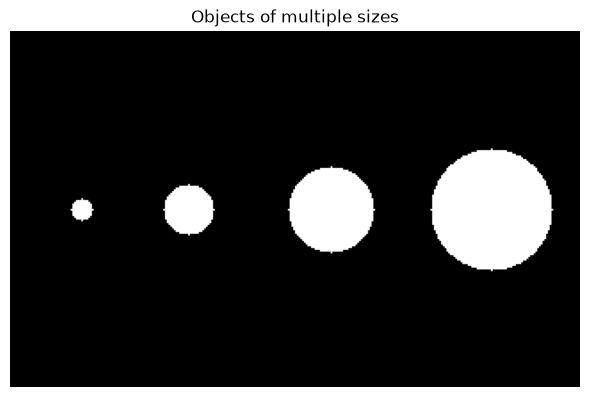

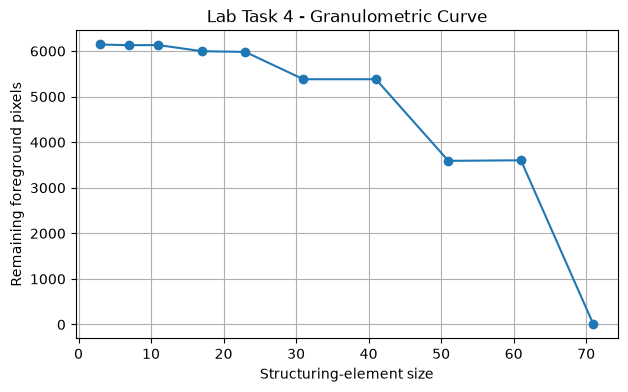

[(3, np.int64(6144)), (7, np.int64(6128)), (11, np.int64(6132)), (17, np.int64(5997)), (23, np.int64(5981)), (31, np.int64(5382)), (41, np.int64(5382)), (51, np.int64(3591)), (61, np.int64(3603)), (71, np.int64(0))]


In [15]:
# Lab Task 4 - Granulometric Curve for Multi-Size Objects
multi = np.zeros((200, 320), dtype=np.uint8)
cv2.circle(multi, (40, 100), 6, 255, -1)
cv2.circle(multi, (100, 100), 14, 255, -1)
cv2.circle(multi, (180, 100), 24, 255, -1)
cv2.circle(multi, (270, 100), 34, 255, -1)

sizes = [3, 7, 11, 17, 23, 31, 41, 51, 61, 71]
remaining = []
for size in sizes:
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    opened = cv2.morphologyEx(multi, cv2.MORPH_OPEN, se)
    remaining.append(np.count_nonzero(opened))

show_images([multi], ["Objects of multiple sizes"], figsize=(6, 4))

plt.figure(figsize=(7, 4))
plt.plot(sizes, remaining, marker="o")
plt.xlabel("Structuring-element size")
plt.ylabel("Remaining foreground pixels")
plt.title("Lab Task 4 - Granulometric Curve")
plt.grid(True)
plt.show()

print(list(zip(sizes, remaining)))

# Lab Task 4 Observation:
# Four circles with radii 6, 14, 24, 34 (diameters ~12, 28, 48, 68) give four distinct
# scales. Expect the curve to stay roughly flat while SE size is smaller than the smallest
# circle's diameter, then drop sharply near SE~13 (smallest circle removed), stay flat,
# drop again near SE~29 (second circle removed), and so on, reaching ~0 once SE size passes
# ~68 (largest circle also removed). Each "step" in the curve corresponds to one object
# scale disappearing - the x-position of each drop estimates the object's size, and the
# height of the drop estimates how much foreground area belongs to objects of that size.

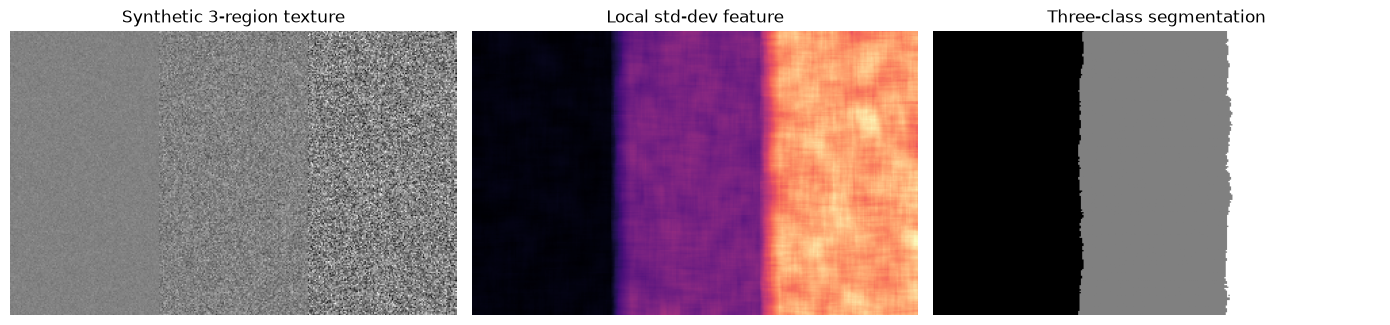

In [16]:
# Lab Task 5 - Texture Segmentation of Multiple Regions
rng2 = np.random.default_rng(11)
tex3 = np.zeros((210, 330), dtype=np.uint8)
tex3[:, :110]    = np.clip(130 + rng2.normal(0, 6,  (210, 110)), 0, 255)
tex3[:, 110:220] = np.clip(130 + rng2.normal(0, 20, (210, 110)), 0, 255)
tex3[:, 220:]    = np.clip(130 + rng2.normal(0, 40, (210, 110)), 0, 255)
tex3 = tex3.astype(np.uint8)

f = tex3.astype(np.float32)
win = 15
mean = cv2.blur(f, (win, win))
mean_sq = cv2.blur(f * f, (win, win))
local_std = np.sqrt(np.maximum(mean_sq - mean * mean, 0))

t1 = np.percentile(local_std, 33)
t2 = np.percentile(local_std, 66)
segments3 = np.zeros_like(tex3)
segments3[local_std > t2] = 255
segments3[(local_std > t1) & (local_std <= t2)] = 128

show_images([tex3, local_std, segments3],
            ["Synthetic 3-region texture", "Local std-dev feature", "Three-class segmentation"],
            figsize=(14, 4), cmaps=["gray", "magma", "gray"])

# Lab Task 5 Justification:
# Feature: local standard deviation (sqrt of local variance) instead of raw variance -
# std scales LINEARLY with the underlying noise amplitude (same units as pixel intensity),
# so differences between regions are more proportionally interpretable than variance, which
# grows quadratically and can make moderate-texture regions look deceptively close to
# low-texture ones. All three regions share the same mean (~130) but differ only in noise
# strength (std 6, 20, 40), so a texture feature - not a brightness threshold - is required.
# Window size: 15x15, same as Experiment 8 - small enough to keep reasonably sharp region
# boundaries, large enough to get a statistically stable local std estimate (a much smaller
# window like 5x5 would be noisy/unstable; much larger like 31x31 would blur the boundary
# between adjacent regions).
# Threshold: two thresholds (33rd and 66th percentile of the std-dev distribution) are used
# instead of one, specifically because there are THREE texture classes here, not two as in
# Experiment 8 - percentile-based cuts automatically adapt to this image's actual std-dev
# range rather than hardcoding fixed numbers, and splitting into equal-sized groups avoids
# biasing the result toward whichever class happens to cover more pixels.